# Анализ датасета "Steel Plates Faults"


Описание: Набор данных о дефектах стальных пластин, классифицированных на 7 различных типов.
Объем: 1941 экземпляр, 27 признаков и 7 бинарных целевых переменных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

path = "C:/Users/mifan/PycharmProjects/AI/33_steel.csv"
df = pd.read_csv(path)

# Создание единого признака 'Fault_Type' для удобства анализа
fault_cols = ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']
df['Fault_Type'] = df[fault_cols].idxmax(axis=1)

print(f"Размер датасета: {df.shape}")
print(f"Количество пропусков: {df.isnull().sum().sum()}")

Размер датасета: (1941, 35)
Количество пропусков: 0


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults,Fault_Type
0,42,50,270900,270944,267,17,44,24220,76,108,...,-0.2913,0.5822,1,0,0,0,0,0,0,Pastry
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,-0.1756,0.2984,1,0,0,0,0,0,0,Pastry
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,-0.1228,0.2150,1,0,0,0,0,0,0,Pastry
3,853,860,369370,369415,176,13,45,18996,99,126,...,-0.1568,0.5212,1,0,0,0,0,0,0,Pastry
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,-0.1992,1.0000,1,0,0,0,0,0,0,Pastry


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
count,1941.00,1941.00,1941.00,1941.00,1941.00,1941.00,1941.00,1941.00,1941.00,1941.00,...,1941.00,1941.00,1941.00,1941.00,1941.0,1941.0,1941.00,1941.00,1941.00,1941.00
mean,571.14,617.96,1650684.87,1650738.71,1893.88,111.86,82.97,206312.15,84.55,130.19,...,0.08,-0.13,0.59,0.08,0.1,0.2,0.04,0.03,0.21,0.35
std,520.69,497.63,1774578.41,1774590.09,5168.46,301.21,426.48,512293.59,32.13,18.69,...,0.50,0.15,0.34,0.27,0.3,0.4,0.19,0.17,0.41,0.48
min,0.00,4.00,6712.00,6724.00,2.00,2.00,1.00,250.00,0.00,37.00,...,-0.99,-1.00,0.12,0.00,0.0,0.0,0.00,0.00,0.00,0.00
25%,51.00,192.00,471253.00,471281.00,84.00,15.00,13.00,9522.00,63.00,124.00,...,-0.33,-0.20,0.25,0.00,0.0,0.0,0.00,0.00,0.00,0.00
50%,435.00,467.00,1204128.00,1204136.00,174.00,26.00,25.00,19202.00,90.00,127.00,...,0.10,-0.13,0.51,0.00,0.0,0.0,0.00,0.00,0.00,0.00
75%,1053.00,1072.00,2183073.00,2183084.00,822.00,84.00,83.00,83011.00,106.00,140.00,...,0.51,-0.07,1.00,0.00,0.0,0.0,0.00,0.00,0.00,1.00
max,1705.00,1713.00,12987661.00,12987692.00,152655.00,10449.00,18152.00,11591414.00,203.00,253.00,...,0.99,0.64,1.00,1.00,1.0,1.0,1.00,1.00,1.00,1.00


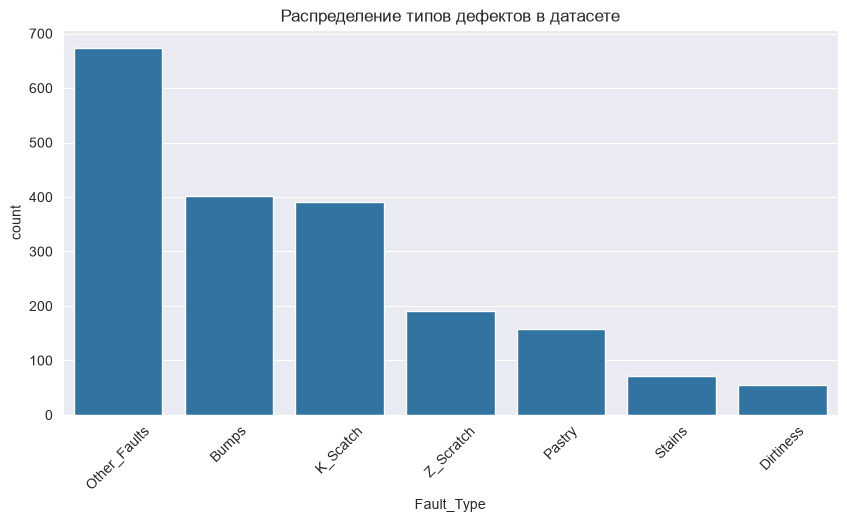

In [2]:
display(df.head())

display(df.describe().round(2))

# Распределение типов дефектов в датасете
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Fault_Type', order=df['Fault_Type'].value_counts().index)
plt.title('Распределение типов дефектов в датасете')
plt.xticks(rotation=45)
plt.show()

## дефекты:
* Pastry - Вздутие (или отслоение поверхности)
* Z_Scratch - продольная царапина
* K_Scatch - поперечная царапина
* Stains - Пятна
* Dirtiness - Загрязнения
* Bumps - выпуклости
* Other_Faults - Прочие дефекты

Средние значения признаков размера и формы по типам дефектов:


,Pixels_Areas,X_Perimeter,Y_Perimeter,Square_Index,Orientation_Index
Fault_Type,,,,,
Bumps,238.47,29.25,23.74,0.71,0.10
Dirtiness,363.49,45.16,57.85,0.23,0.60
K_Scatch,7622.65,384.66,255.35,0.60,-0.30
Other_Faults,584.37,52.79,43.87,0.54,0.11
Pastry,561.62,35.56,57.73,0.35,0.64
Stains,19.92,8.22,5.32,0.71,-0.27
Z_Scratch,506.59,56.47,49.67,0.57,0.26


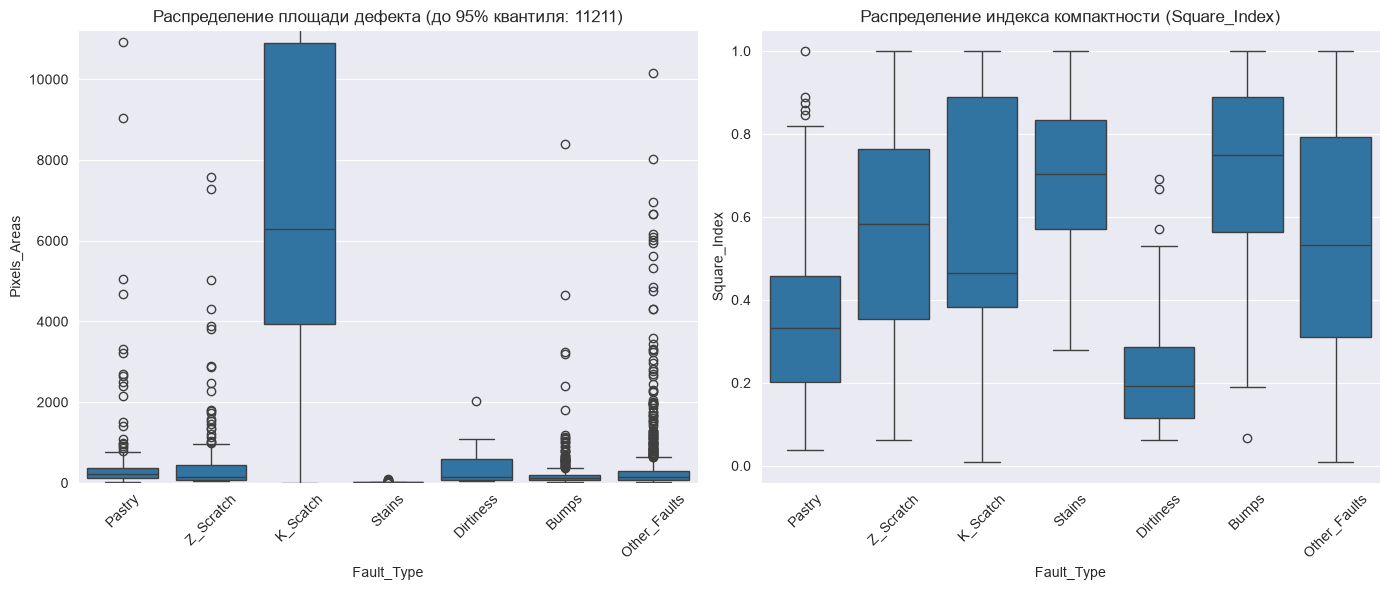

In [3]:
# Признаки, отвечающие за размер и форму
size_shape_features = [
    'Pixels_Areas',       # Площадь дефекта в пикселях
    'X_Perimeter',        # Периметр по оси X
    'Y_Perimeter',        # Периметр по оси Y
    'Square_Index',       # Индекс, характеризующий компактность (близость к квадрату/кругу)
    'Orientation_Index'   # Индекс ориентации дефекта в пространстве
]

# Вычисление средних значений для каждого типа дефекта
mean_stats = df.groupby('Fault_Type')[size_shape_features].mean().round(2)
print("Средние значения признаков размера и формы по типам дефектов:")
display(mean_stats)


fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# График площади с ограничением по квантилю
q95 = df['Pixels_Areas'].quantile(0.95)
sns.boxplot(data=df, x='Fault_Type', y='Pixels_Areas', ax=axes[0])
axes[0].set_ylim(0, q95)
axes[0].set_title(f'Распределение площади дефекта (до 95% квантиля: {q95:.0f})')
axes[0].tick_params(axis='x', rotation=45)

# График индекса компактности
sns.boxplot(data=df, x='Fault_Type', y='Square_Index', ax=axes[1])
axes[1].set_title('Распределение индекса компактности (Square_Index)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

размеры и формы дефектов различаются геометрически:

* Размеры: K_Scatch значительно крупнее других дефектов (средняя площадь 7623 против 20-584 у остальных)
* Формы:
* Bumps и Stains более компактные (Square_Index = 0.71);
* Dirtiness имеет неправильную форму (Square_Index = 0.23);
* K_Scatch вытянутый (большой периметр относительно площади);
* Ориентация: Разные типы дефектов имеют различную ориентацию (Orientation_Index от -0.30 до 0.64)

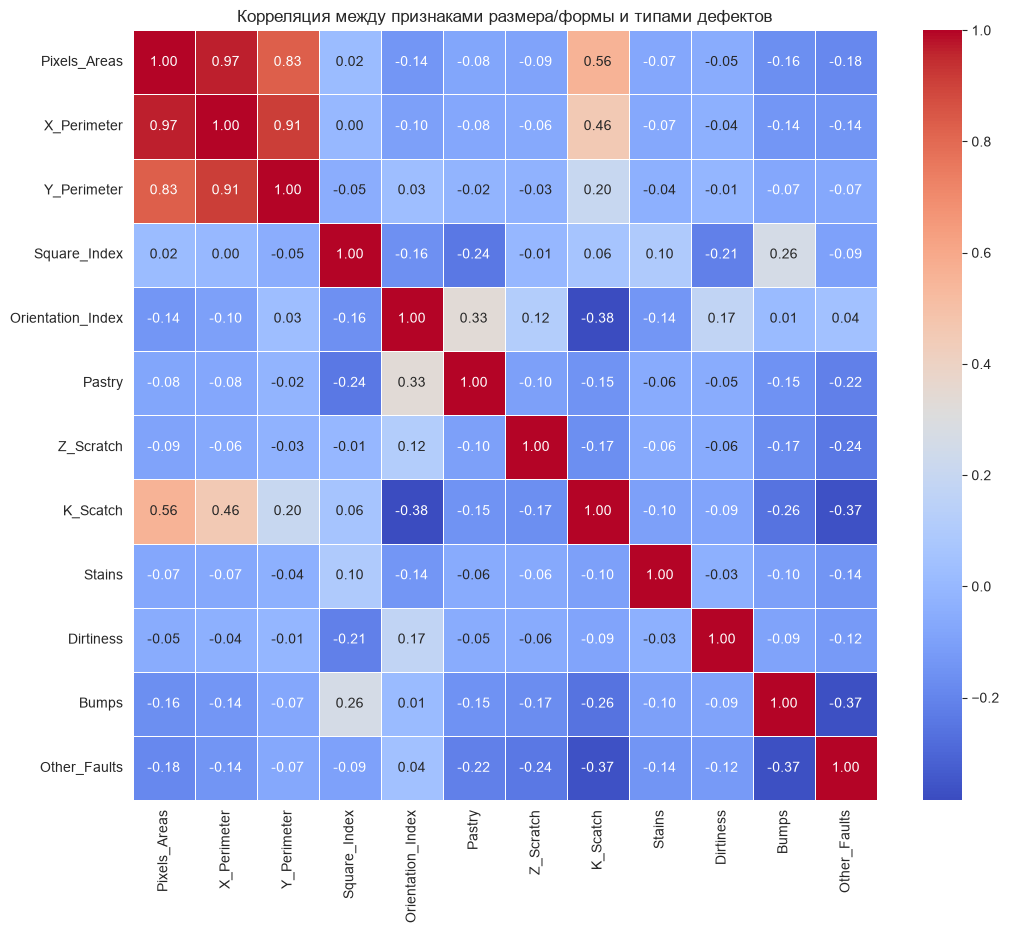

In [4]:
# Построение матрицы корреляции между геометрическими признаками и типами дефектов
# (для наглядности берем только целевые классы и признаки формы)
features_to_corr = size_shape_features + fault_cols
corr_matrix = df[features_to_corr].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Корреляция между признаками размера/формы и типами дефектов')
plt.show()

Доля правильных ответов (accuracy): 0.802
              precision    recall  f1-score   support

       Bumps       0.75      0.72      0.73        81
   Dirtiness       0.89      0.73      0.80        11
    K_Scatch       0.97      0.91      0.94        78
Other_Faults       0.72      0.85      0.78       135
      Pastry       0.64      0.50      0.56        32
      Stains       0.92      0.86      0.89        14
   Z_Scratch       0.97      0.84      0.90        38

    accuracy                           0.80       389
   macro avg       0.84      0.77      0.80       389
weighted avg       0.81      0.80      0.80       389



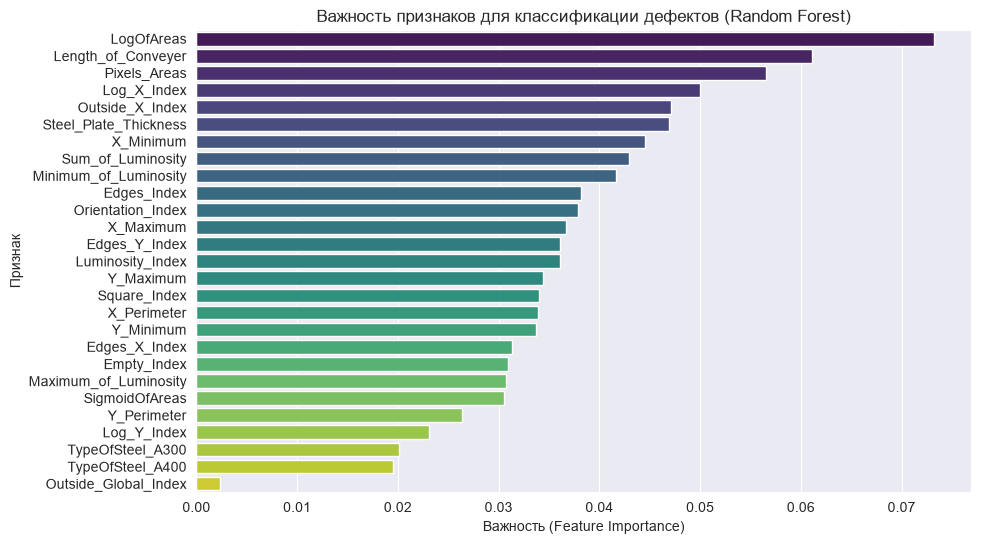

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

features = df.drop(columns=fault_cols + ['Fault_Type']).columns
X = df[features]
y = df['Fault_Type']

# stratify по y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)

print("Доля правильных ответов (accuracy):", round(accuracy_score(y_test, pred), 3))
print(classification_report(y_test, pred, digits=2))

# Смотрим важность признаков
importances = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=importances.values,
    y=importances.index,
    hue=importances.index,
    palette='viridis',
    legend=False
)
plt.title('Важность признаков для классификации дефектов (Random Forest)')
plt.xlabel('Важность (Feature Importance)')
plt.ylabel('Признак')
plt.show()

Модель угадывает тип дефекта в 80% случаев (accuracy = 0.802). Лучше всего распознаётся K_Scatch - он огромный, средняя площадь 7623 против 20–584 у остальных, его видно по размеру. Хуже всего - Pastry: модель находит только половину вздутий.

Рвзмер дефекта является ключевым фактором для классификации

Запуск модели Random Forest подтвердил гипотезу, но добавил важные нюансы:
* Признак `LogOfAreas` (логарифм площади) второй по важности, что математически подтверждает: размер дефекта является ключевым фактором для его классификации.
* Модель также выделила контекстные признаки помимо геометрических дефектов: `Length_of_Conveyer` и `Steel_Plate_Thickness`. Это толщина стального листа и этап производственного процесса (длина конвейера), на котором дефект возник.

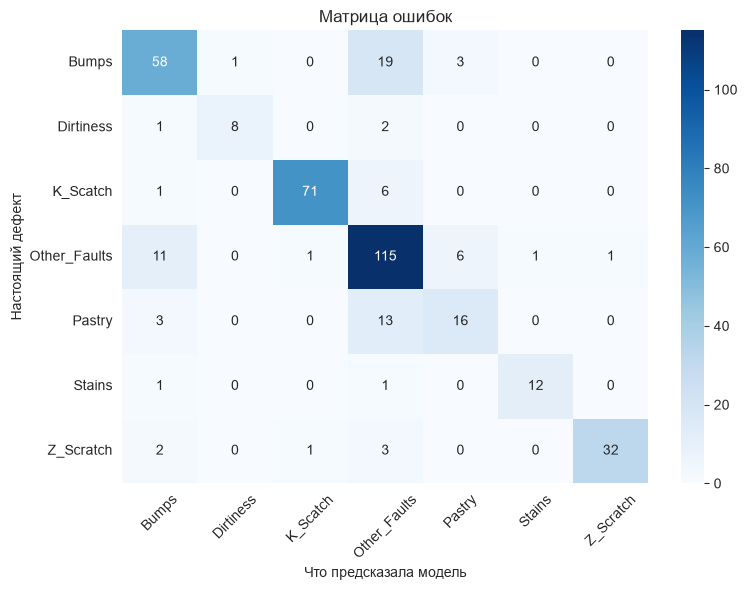

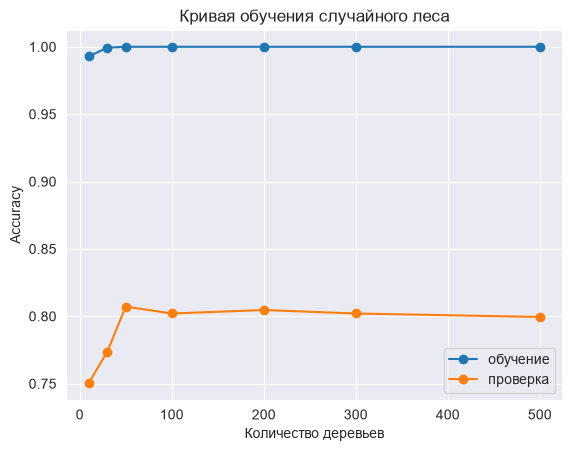

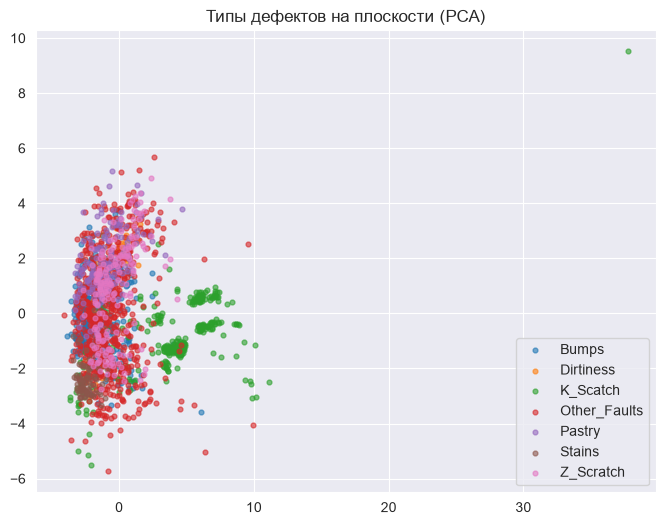

In [12]:
# Матрица ошибок
cm = confusion_matrix(y_test, pred, labels=rf.classes_)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=rf.classes_, yticklabels=rf.classes_)
plt.xlabel('Что предсказала модель'); plt.ylabel('Настоящий дефект')
plt.title('Матрица ошибок'); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

# Кривая обучения
train_acc, test_acc, ns = [], [], [10, 30, 50, 100, 200, 300, 500]
for n in ns:
    m = RandomForestClassifier(n_estimators=n, random_state=42).fit(X_train, y_train)
    train_acc.append(m.score(X_train, y_train)); test_acc.append(m.score(X_test, y_test))
plt.plot(ns, train_acc, 'o-', label='обучение'); plt.plot(ns, test_acc, 'o-', label='проверка')
plt.xlabel('Количество деревьев'); plt.ylabel('Accuracy'); plt.legend()
plt.title('Кривая обучения случайного леса'); plt.show()

# Классы на плоскости (PCA)
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
XY = PCA(2, random_state=42).fit_transform(StandardScaler().fit_transform(X))
plt.figure(figsize=(8, 6))
for fault in sorted(y.unique()):
    mask = (y == fault).values
    plt.scatter(XY[mask, 0], XY[mask, 1], s=12, alpha=.6, label=fault)
plt.legend(); plt.title('Типы дефектов на плоскости (PCA)'); plt.show()

на матрице ошибок видно: K_Scatch почти не путается ни с чем. Главная путаница вокруг Other_Faults: у него полнота 0.85, но точность 0.72 - то есть модель записывает в «прочие» всё непонятное, туда чаще всего уходят Pastry и Bumps. Это логично: Other_Faults - сборная категория без чёткой формы.


Кривая обучения: на обучающих данных accuracy почти 100%, на проверке растёт примерно до 0.80 и после 100 деревьев выходит на плато - больше деревьев не нужно. Разрыв между обучением и проверкой - модель частично запоминает данные.
На PCA-графике K_Scatch стоит отдельным облаком, остальные классы сильно перемешаны - поэтому 100% точности тут не будет.

In [13]:
# 1. Перебор параметров + балансировка классов (редким дефектам даём больший вес)
rows = []
for leaf in [1, 2, 4]:
    for cw in [None, 'balanced']:
        m = RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf,
                                   class_weight=cw, random_state=42).fit(X_train, y_train)
        rows.append({'min_samples_leaf': leaf, 'class_weight': str(cw),
                     'accuracy': round(m.score(X_test, y_test), 3)})
print(pd.DataFrame(rows).sort_values('accuracy', ascending=False).to_string(index=False))

# 2. Другие алгоритмы
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

gb = GradientBoostingClassifier(random_state=42).fit(X_train, y_train)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
print("Градиентный бустинг:", round(gb.score(X_test, y_test), 3))
print("Логистическая регрессия:", round(lr.score(X_test, y_test), 3))

# 3. Выкидываем слабые признаки - оставляем 15 самых важных
imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
top15 = imp.head(15).index
rf_top = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced',
                                random_state=42).fit(X_train[top15], y_train)
print("Только 15 важных признаков:", round(rf_top.score(X_test[top15], y_test), 3))

 min_samples_leaf class_weight  accuracy
                1         None     0.802
                2         None     0.794
                4         None     0.794
                1     balanced     0.781
                2     balanced     0.769
                4     balanced     0.748
Градиентный бустинг: 0.792
Логистическая регрессия: 0.728
Только 15 важных признаков: 0.763


после трех способов улучшения - ни один не обогнал обычный лес (0.802):
* Балансировка классов сделала хуже: 0.781 и ниже. Она нужна, только если важнее ловить редкие дефекты любой ценой, а не общая точность.
* Градиентный бустинг дал 0.792 - чуть хуже леса. Логистическая регрессия 0.728 - сильно хуже, значит границы между дефектами нелинейные.
* Если оставить только 15 важных признаков, точность падает до 0.763 - слабые признаки всё-таки несут информацию, выкидывать их не стоит.
* В итоге оставил случайный лес на всех 27 признаках без балансировки, accuracy 0.802.

In [22]:
from sklearn.ensemble import ExtraTreesClassifier, VotingClassifier, HistGradientBoostingClassifier

# Новые признаки: пропорции и яркость дефекта
X2 = X.copy()
X2['X_size'] = df['X_Maximum'] - df['X_Minimum']          # ширина дефекта
X2['Y_size'] = df['Y_Maximum'] - df['Y_Minimum']          # высота дефекта
X2['fill_ratio'] = df['Pixels_Areas'] / (X2['X_size'] * X2['Y_size']).replace(0, 1)  # заполненность
X2['aspect'] = X2['X_size'] / X2['Y_size'].replace(0, 1)  # вытянутость
X2['lum_range'] = df['Maximum_of_Luminosity'] - df['Minimum_of_Luminosity'] # яркость
X2['lum_mean'] = df['Sum_of_Luminosity'] / df['Pixels_Areas'].replace(0, 1)

tr2, te2 = X2.loc[X_train.index], X2.loc[X_test.index]

rf_sqrt = RandomForestClassifier(n_estimators=500, max_features='sqrt', random_state=42, n_jobs=-1)
et = ExtraTreesClassifier(n_estimators=500, random_state=42, n_jobs=-1)
vote = VotingClassifier([('rf', rf_sqrt), ('et', et),
                         ('gb', HistGradientBoostingClassifier(random_state=42))], voting='soft')

for name, model, a, b in [
    ('Лес sqrt, старые признаки', RandomForestClassifier(500, max_features='sqrt', random_state=42, n_jobs=-1), X_train, X_test),
    ('Лес sqrt + новые признаки', rf_sqrt, tr2, te2),
    ('ExtraTrees + новые признаки', et, tr2, te2),
    ('Ансамбль из трёх моделей', vote, tr2, te2)]:
    model.fit(a, y_train)
    print(f"{name}: тест = {model.score(b, y_test):.3f}")

Лес sqrt, старые признаки: тест = 0.799
Лес sqrt + новые признаки: тест = 0.781
ExtraTrees + новые признаки: тест = 0.787
Ансамбль из трёх моделей: тест = 0.805


Добавил 6 новых признаков (пропорции и яркость дефекта) и попробовал ExtraTrees и ансамбль из трёх моделей. Лучший результат  у ансамбля - 0.805.

Задача - классификация на 7 типов, классы несбалансированы. Лучшая модель - ансамбль accuracy  0.805. Перебор параметров, балансировка классов, бустинг, линейная модель, удаление слабых признаков, новые признаки и ансамбль проверены, заметного прироста нет. Лучше всего распознаётся K_Scatch (f1 = 0.94, он в 10–300 раз крупнее остальных), хуже всего Pastry (f1 = 0.56) - модель находит только половину вздутий и часто записывает их в «прочие». Главные признаки - размер дефекта, толщина листа и длина конвейера. Для лучших показателей нужны новые данные.